# From Sound to Spectrogram to MFCCs

A radio station keeps every broadcast, and its archivist wants to mark where the talk ends and
the music begins. A listener needs a fraction of a second to tell a reading from violins. As
lists of numbers, the two look alike: values that swing up and down around zero. This notebook
follows the book sections *From Sound to Spectrogram* and *Perceptual Features* with the two
running clips of the chapter, a LibriVox reading and Brahms's Hungarian Dance No. 5. It turns the
samples into a spectrogram, computes energy, zero-crossing rate, and spectral features per frame
and per segment, and builds MFCCs step by step. At the end, three numbers per recording separate
the readings from the music.

**Learning goals:**
- Read a recording as samples and see what the sampling rate decides
- Compute the spectrum of one frame and the spectrogram of a whole clip, and see the trade-off
  between time and frequency resolution
- Compute short-time energy, zero-crossing rate, LSTER, and HZCRR, and read them for speech and music
- Compute spectral centroid, roll-off, bandwidth, and flux, and the A-weighted loudness
- Build the mel filter bank and compute MFCCs in five steps

**Prerequisites:** none. No background in signal processing is needed.

**Data:** librosa example recordings, the same clips as the book. They are downloaded on the
first run (a few MB each) into the librosa cache. The credits are listed at the end.

## Setup

`ch11_audio.py` loads the clips and holds the formulas that later demos of this chapter reuse.
In this notebook, we compute each feature step by step in the cells and use the module only for
loading, framing, and drawing.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
from IPython.display import Audio, display
from scipy.signal import find_peaks

from shared.display import print_table, display_md
from ch11_audio import (SR, CLIPS, SPEECH_C, MUSIC_C, load, credits, frames, stft_db,
                        show_spectrogram, mel_bank, mfcc)

speech, music = load("libri1"), load("brahms")          # float samples at 22,050 Hz, mono
clips = {"LibriVox reading": (speech, SPEECH_C), "Brahms": (music, MUSIC_C)}

## 1. Two Recordings as Lists of Numbers

A computer stores sound as samples $x(n)$: the amplitude at the microphone, measured $f_s$ times
per second. Both clips are stored with $f_s = 22{,}050$ samples per second.

In [2]:
display_md(
    "| Clip | Duration | Samples | Smallest value | Largest value |\n"
    "|---|---|---|---|---|\n"
    + "\n".join(f"| {name} | {len(y) / SR:.1f} s | {len(y):,} | {y.min():.3f} | {y.max():.3f} |"
                for name, (y, _) in clips.items())
)

| Clip | Duration | Samples | Smallest value | Largest value |
|---|---|---|---|---|
| LibriVox reading | 14.8 s | 327,222 | -0.809 | 0.501 |
| Brahms | 45.8 s | 1,010,880 | -0.646 | 0.783 |

Listen to the first five seconds of the reading (first player) and of Brahms (second player).

In [3]:
for y, _ in clips.values():
    display(Audio(y[:5 * SR], rate=SR))

The waveform plots the samples over time. On the scale of seconds, the reading shows bursts of
syllables separated by short pauses, and the orchestra a more continuous level. Zoomed in to
50 ms, both are curves that swing around zero, and the picture does not say which tones produce
them.

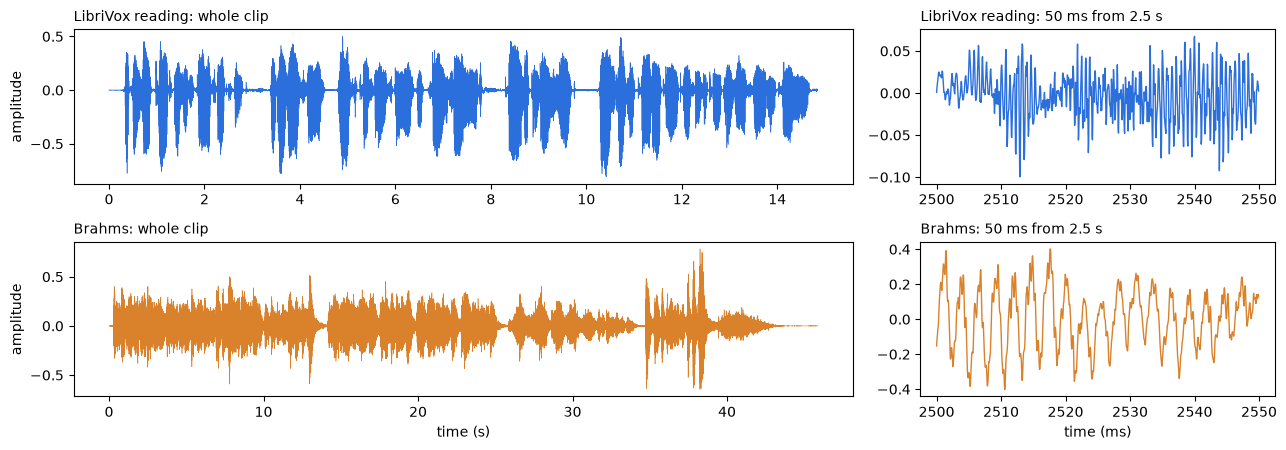

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[2.2, 1]))
for row, (name, (y, color)) in enumerate(clips.items()):
    t = np.arange(len(y)) / SR
    axes[row, 0].plot(t, y, color=color, lw=0.4)
    axes[row, 0].set_title(f"{name}: whole clip", fontsize=10, loc="left")
    a = int(2.5 * SR)                                   # 50 ms from 2.5 s on
    axes[row, 1].plot(t[a:a + int(0.05 * SR)] * 1000, y[a:a + int(0.05 * SR)], color=color, lw=1)
    axes[row, 1].set_title(f"{name}: 50 ms from 2.5 s", fontsize=10, loc="left")
axes[1, 0].set_xlabel("time (s)")
axes[1, 1].set_xlabel("time (ms)")
for ax in axes[:, 0]:
    ax.set_ylabel("amplitude")
fig.tight_layout()
plt.show()

## 2. Sampling and Aliasing

A sampled signal can represent frequencies up to half the sampling rate, $f_\text{max} = f_s / 2$.
The two clips represent frequencies up to 11,025 Hz. Frequencies above $f_s / 2$ do not
disappear: they fold back and appear as tones that were never there. The book's example is a
30 kHz component sampled at 48 kHz. We sample such a tone for one second and look for the
strongest frequency in its spectrum.

In [5]:
fs = 48000
n = np.arange(fs)                                       # one second of samples
x = np.sin(2 * np.pi * 30000 * n / fs)                  # a 30 kHz tone, above fs / 2 = 24 kHz
X = np.abs(np.fft.rfft(x))
display_md(f"A 30,000 Hz tone sampled at {fs:,} Hz shows its strongest frequency at "
           f"**{np.argmax(X) * fs / len(x):,.0f} Hz**, that is, at {fs:,} - 30,000 Hz.")

A 30,000 Hz tone sampled at 48,000 Hz shows its strongest frequency at **18,000 Hz**, that is, at 48,000 - 30,000 Hz.

Recording devices therefore remove frequencies above $f_s / 2$ with a low-pass filter before
sampling.

## 3. From Waveform to Spectrum

A violin note is a sum of sine waves at its fundamental and at multiples of it. The discrete
Fourier transform separates them:

$$
X(k) = \sum_{n=0}^{N-1} x(n) \cdot e^{-\mathrm{i}\, 2\pi k n / N}, \qquad f(k) = k \cdot \frac{f_s}{N}
$$

We take one frame of 40 ms from each clip, $N = 882$ samples, multiply it with a Hann window that
fades the frame in and out, and compute its spectrum with the FFT. The real-valued signal gives
the bins $0 \le k \le N/2$, which cover 0 to 11,025 Hz in steps of $f_s / N$.

In [6]:
N = int(0.040 * SR)                                     # 40 ms frame
w = np.hanning(N)
f = np.arange(N // 2 + 1) * SR / N                      # bin frequencies

spectrum = {}
for name, start in (("LibriVox reading", 2.0), ("Brahms", 2.5)):
    y = clips[name][0]
    a = int(start * SR)
    spectrum[name] = (start, np.abs(np.fft.rfft(y[a:a + N] * w)))

display_md(f"$N$ = {N} samples, {len(f)} bins from 0 to {f[-1]:,.0f} Hz, "
           f"$\\Delta f = f_s / N$ = {SR / N:.0f} Hz")

$N$ = 882 samples, 442 bins from 0 to 11,025 Hz, $\Delta f = f_s / N$ = 25 Hz

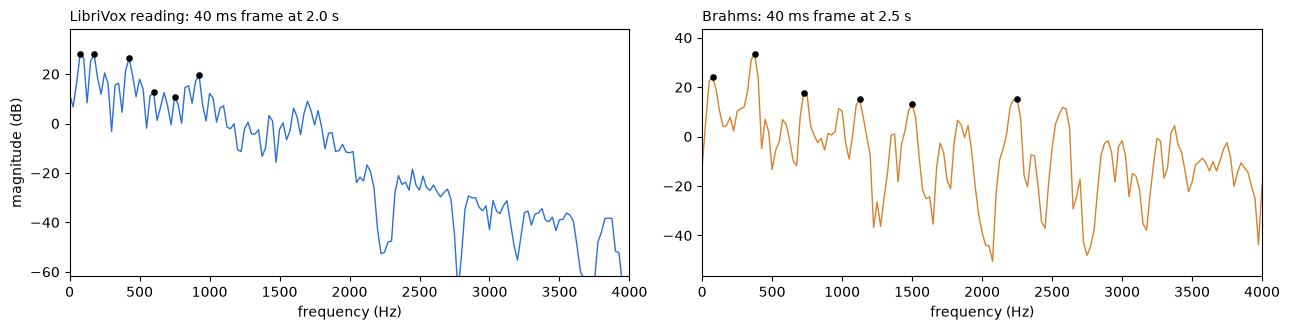

| Frame            | Six strongest peaks (Hz)       |
|:-----------------|:-------------------------------|
| LibriVox reading | 75, 175, 425, 600, 750, 925    |
| Brahms           | 75, 375, 725, 1125, 1500, 2250 |

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
rows = []
for ax, (name, (start, X)) in zip(axes, spectrum.items()):
    db = 20 * np.log10(X + 1e-10)
    peaks, _ = find_peaks(db, distance=4)
    top = np.sort(peaks[np.argsort(db[peaks])[::-1][:6]])     # the six strongest peaks
    ax.plot(f, db, color=clips[name][1], lw=1)
    ax.scatter(f[top], db[top], color="black", s=14, zorder=3)
    ax.set_xlim(0, 4000)
    ax.set_ylim(db.max() - 90, db.max() + 10)
    ax.set_title(f"{name}: 40 ms frame at {start} s", fontsize=10, loc="left")
    ax.set_xlabel("frequency (Hz)")
    rows.append([name, ", ".join(f"{f[k]:.0f}" for k in top)])
axes[0].set_ylabel("magnitude (dB)")
fig.tight_layout()
plt.show()
print_table(rows, headers=["Frame", "Six strongest peaks (Hz)"])

The Brahms frame has peaks at nearly regular distances, the harmonics of the notes the violins
play. The frame of the reading has its strongest peaks at low frequencies, the harmonics of the
voice, and fewer peaks above 1000 Hz. On a grid of 25 Hz, each peak is only located to within one bin.

## 4. The Short-Time Fourier Transform

A single spectrum of a whole clip would contain all notes but not their order. The short-time
Fourier transform cuts the recording into frames of $N$ samples, moves each frame forward by a
hop of $H$ samples, and transforms each windowed frame:

$$
X(t,k) = \sum_{n=0}^{N-1} x(tH + n) \cdot w(n) \cdot e^{-\mathrm{i}\, 2\pi k n / N}
$$

The squared magnitudes in decibels form the spectrogram: time runs to the right, frequency
upwards, and the color shows the energy. We use frames of 40 ms with a hop of 20 ms.

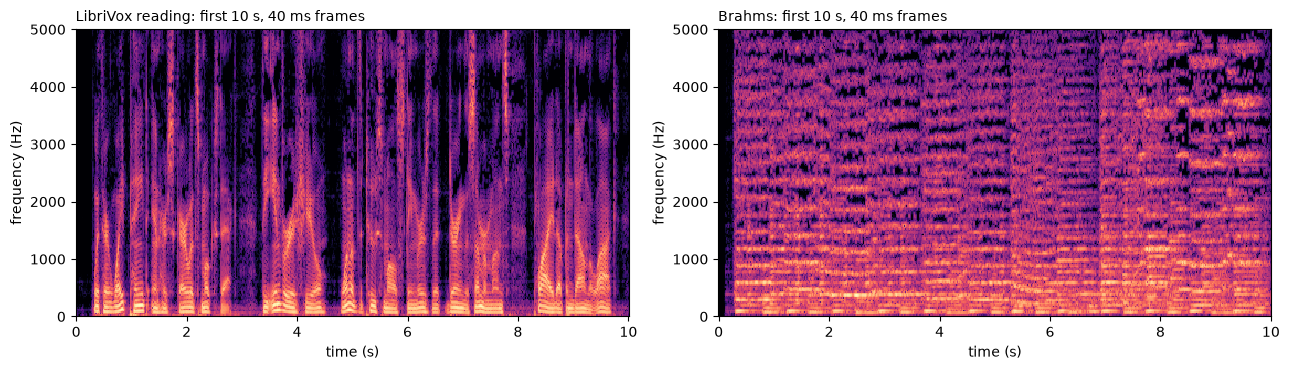

The 14.8-second reading becomes **741 spectra of 442 bins** each.

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (name, (y, _)) in zip(axes, clips.items()):
    S, n, hop = stft_db(y[:10 * SR], 40, 20)
    show_spectrogram(ax, S, n, hop, f_max=5000, title=f"{name}: first 10 s, 40 ms frames")
fig.tight_layout()
plt.show()

F, n = frames(speech)                                   # without padding at the ends, as in the book
display_md(f"The {len(speech) / SR:.1f}-second reading becomes **{F.shape[0]} spectra of "
           f"{n // 2 + 1} bins** each.")

The reading shows stacks of thin harmonic lines that bend with the intonation, broken by gaps at
the pauses, and short bursts of noise up to high frequencies for the hissing consonants. The
violins show long horizontal harmonic lines that change step by step from note to note.

## 5. The Time-Frequency Trade-off

The frequency resolution of a frame is $\Delta f = f_s / N = 1 / T$, where $T$ is its duration. A
longer frame gives a finer grid but averages over a longer time. The book shows the first four
seconds of the Brahms clip with frames of 10, 40, and 160 ms, each with a hop of a quarter frame.

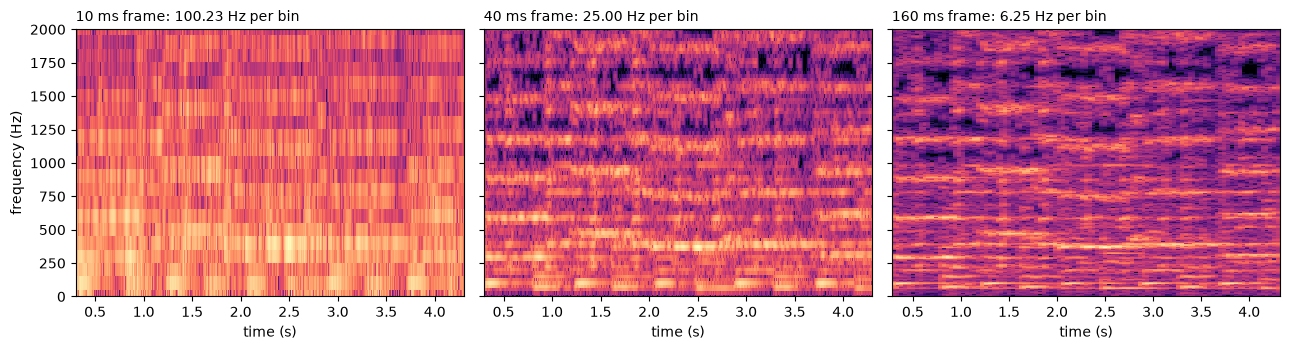

In [9]:
t0, t1 = 0.3, 4.3                                       # skip the silent start, as in the book
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, ms in zip(axes, (10, 40, 160)):
    S, n, hop = stft_db(music[int(t0 * SR):int(t1 * SR)], ms, ms / 4)
    show_spectrogram(ax, S, n, hop, t0=t0, f_max=2000, title=f"{ms} ms frame: {SR / n:.2f} Hz per bin")
for ax in axes[1:]:
    ax.set_ylabel("")
fig.tight_layout()
plt.show()

With 10 ms frames, the harmonics merge into broad bands, but every change of note is a sharp
vertical edge. With 160 ms frames, the harmonics are thin lines, but the note changes blur. The
40 ms frames keep both visible.

Does a higher sampling rate help? We load the reading at three rates and frame it into 40 ms
pieces each time.

In [10]:
rows = []
for fs in (16000, 22050, 48000):
    F_fs, n_fs = frames(load("libri1", fs), fs)
    rows.append([f"{fs:,} Hz", n_fs, n_fs // 2 + 1, f"{fs / 2:,.0f} Hz", f"{fs / n_fs:.2f} Hz"])
print_table(rows, headers=["Sampling rate", "Samples per 40 ms", "Bins", "Highest bin", "Bin spacing"])

| Sampling rate   |   Samples per 40 ms |   Bins | Highest bin   | Bin spacing   |
|:----------------|--------------------:|-------:|:--------------|:--------------|
| 16,000 Hz       |                 640 |    321 | 8,000 Hz      | 25.00 Hz      |
| 22,050 Hz       |                 882 |    442 | 11,025 Hz     | 25.00 Hz      |
| 48,000 Hz       |                1920 |    961 | 24,000 Hz     | 25.00 Hz      |

A higher sampling rate adds bins at the top of the spectrum, but the spacing stays at 25 Hz. Only
a longer frame makes the bins narrower.

## 6. Features in the Time Domain

From here on, frame $t$ holds the samples $x_t(n) = x(tH + n)$ of a 40 ms frame with a hop of
20 ms. The **short-time energy** is the mean of the squared amplitudes, and the
**zero-crossing rate** counts the sign changes:

$$
E(t) = \frac{1}{N} \sum_{n=0}^{N-1} x_t(n)^2, \qquad
Z(t) = \frac{1}{2N} \sum_{n=1}^{N-1} \bigl|\operatorname{sgn}(x_t(n)) - \operatorname{sgn}(x_t(n-1))\bigr|
$$

In [11]:
def time_features(y):
    F, N = frames(y)                                    # one row per 40 ms frame
    E = np.mean(F ** 2, axis=1)                         # linear energy
    s = np.where(F >= 0, 1, -1)                         # sgn, with zero counted as positive
    Z = np.sum(np.abs(np.diff(s, axis=1)), axis=1) / (2 * N)
    return E, Z

E, Z = {}, {}
for name, (y, _) in clips.items():
    E[name], Z[name] = time_features(y)

The plot shows the first five seconds of the reading. The energy in decibels, $10 \log_{10} E(t)$,
drops by 20 to 30 dB in the pauses. The zero-crossing rate is low in the vowels and jumps in the
hissing consonants.

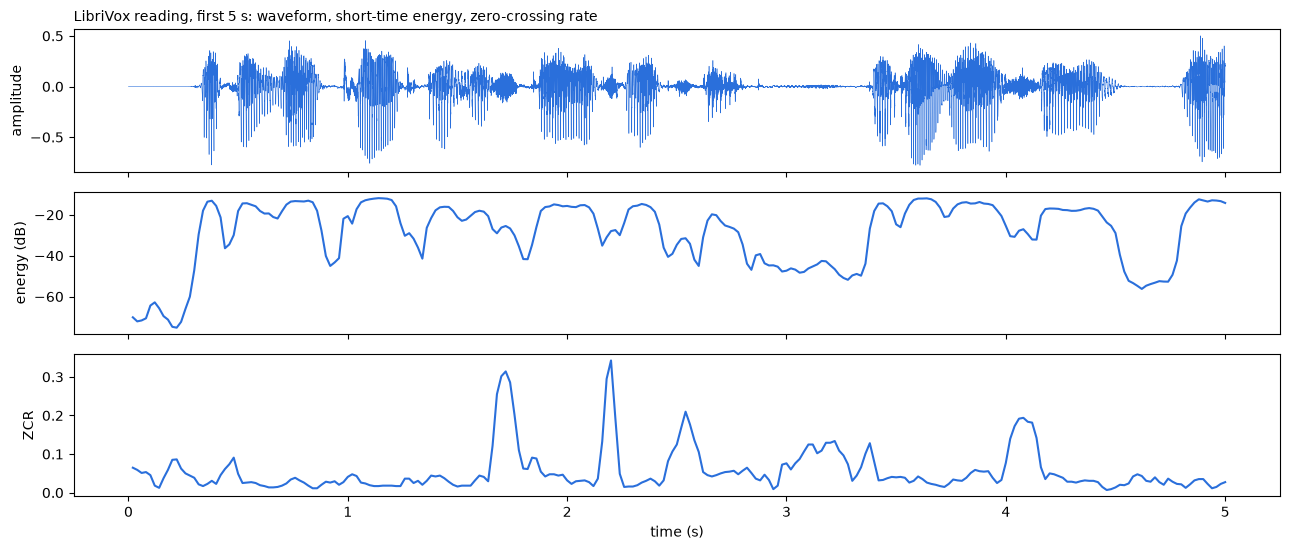

Frames with the highest ZCR in the whole reading, at 7.18 s (0.37), 7.78 s (0.38), 10.54 s (0.42), 10.56 s (0.44), 10.58 s (0.43). Play `Audio(speech[int(t * SR) - 4000:int(t * SR) + 4000], rate=SR)` around one of them.

In [12]:
name, y = "LibriVox reading", speech
t_frames = np.arange(len(E[name])) * 0.020 + 0.020      # frame centers
k = int(5 / 0.020)
fig, axes = plt.subplots(3, 1, figsize=(13, 5.6), sharex=True)
axes[0].plot(np.arange(5 * SR) / SR, y[:5 * SR], color=SPEECH_C, lw=0.4)
axes[0].set_ylabel("amplitude")
axes[1].plot(t_frames[:k], 10 * np.log10(E[name][:k]), color=SPEECH_C)
axes[1].set_ylabel("energy (dB)")
axes[2].plot(t_frames[:k], Z[name][:k], color=SPEECH_C)
axes[2].set_ylabel("ZCR")
axes[2].set_xlabel("time (s)")
axes[0].set_title("LibriVox reading, first 5 s: waveform, short-time energy, zero-crossing rate",
                  fontsize=10, loc="left")
fig.tight_layout()
plt.show()

top = np.argsort(Z[name])[::-1][:5]
display_md("Frames with the highest ZCR in the whole reading, at "
           + ", ".join(f"{t_frames[i]:.2f} s ({Z[name][i]:.2f})" for i in sorted(top))
           + ". Play `Audio(speech[int(t * SR) - 4000:int(t * SR) + 4000], rate=SR)` around one of them.")

## 7. Segment Statistics: LSTER and HZCRR

A single 40 ms frame says little about whether someone is speaking. A segment of 4 seconds holds
$M = (4000 - 40)/20 + 1 = 199$ frames, and two ratios were designed to separate speech from music:

$$
r_\text{LSTER}(j) = \frac{\bigl|\{t \in S_j : E(t) < \tfrac{1}{2}\, \bar{E}_j\}\bigr|}{M}, \qquad
r_\text{HZCRR}(j) = \frac{\bigl|\{t \in S_j : Z(t) > \tfrac{3}{2}\, \bar{Z}_j\}\bigr|}{M}
$$

LSTER uses the linear energy, because "half the mean" makes no sense on decibel values. As in the
book, the segments start 1 second apart.

In [13]:
M, step = (4000 - 40) // 20 + 1, 1000 // 20             # 199 frames per segment, 50 frames per second

def segment_ratios(E, Z):
    rows = []
    for a in range(0, len(E) - M + 1, step):
        e, z = E[a:a + M], Z[a:a + M]
        rows.append((np.mean(e < 0.5 * e.mean()), np.mean(z > 1.5 * z.mean())))
    return np.array(rows)                               # one row (LSTER, HZCRR) per segment

seg = {name: segment_ratios(E[name], Z[name]) for name in clips}

rng = lambda v: f"{v.mean():.2f} ({v.min():.2f} to {v.max():.2f})"
print_table(
    [["Frame ZCR: mean (median)"] + [f"{Z[c].mean():.3f} ({np.median(Z[c]):.3f})" for c in clips],
     ["Segments"] + [str(len(seg[c])) for c in clips],
     ["LSTER: mean (range)"] + [rng(seg[c][:, 0]) for c in clips],
     ["HZCRR: mean (range)"] + [rng(seg[c][:, 1]) for c in clips]],
    headers=[""] + list(clips),
)

|                          | LibriVox reading    | Brahms              |
|:-------------------------|:--------------------|:--------------------|
| Frame ZCR: mean (median) | 0.058 (0.036)       | 0.121 (0.095)       |
| Segments                 | 11                  | 42                  |
| LSTER: mean (range)      | 0.47 (0.42 to 0.55) | 0.35 (0.12 to 0.83) |
| HZCRR: mean (range)      | 0.19 (0.17 to 0.22) | 0.09 (0.01 to 0.31) |

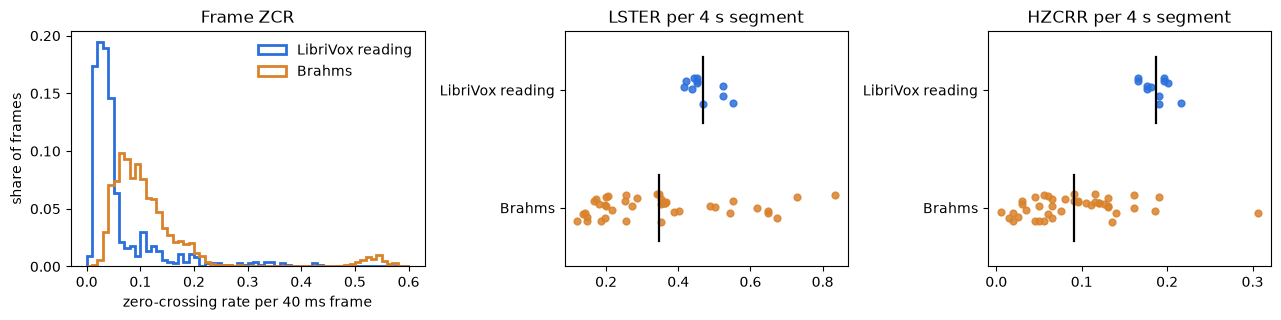

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), gridspec_kw=dict(width_ratios=[1.25, 1, 1]))
bins = np.arange(0, 0.61, 0.01)
for i, (name, (_, color)) in enumerate(clips.items()):
    axes[0].hist(Z[name], bins=bins, weights=np.full(len(Z[name]), 1 / len(Z[name])),
                 histtype="step", color=color, lw=2, label=name)
    for ax, col in ((axes[1], 0), (axes[2], 1)):
        v = seg[name][:, col]
        ax.scatter(v, np.full(len(v), 1 - i) + np.random.default_rng(0).uniform(-0.12, 0.12, len(v)),
                   color=color, s=24, alpha=0.85)
        ax.plot([v.mean()] * 2, [0.72 - i, 1.28 - i], color="black", lw=1.6)
axes[0].set(xlabel="zero-crossing rate per 40 ms frame", ylabel="share of frames", title="Frame ZCR")
axes[0].legend(frameon=False)
for ax, title in ((axes[1], "LSTER per 4 s segment"), (axes[2], "HZCRR per 4 s segment")):
    ax.set(title=title, yticks=[1, 0], yticklabels=list(clips), ylim=(-0.5, 1.5))
fig.tight_layout()
plt.show()

The frame ZCR points the other way than one might expect: Brahms crosses zero about twice as
often on average, because the strings produce many high harmonics. Speech does not cross zero
more often on average; it varies more from frame to frame, and the two ratios measure exactly
this variation. The segments of the reading lie in narrow bands. The Brahms segments spread
widely, and the ones with a speech-like LSTER sit at the end of the clip, where the orchestra
pauses, accents, and fades out.

In [15]:
low = seg["LibriVox reading"].min(axis=0)               # lowest LSTER and HZCRR of the reading
like = seg["Brahms"] >= low                             # Brahms segments that reach them
display_md(
    f"Brahms segments with at least the lowest LSTER of the reading ({low[0]:.2f}): "
    f"**{like[:, 0].sum()}**, starting at {', '.join(str(s) for s in np.where(like[:, 0])[0])} s. "
    f"With at least its lowest HZCRR ({low[1]:.2f}): **{like[:, 1].sum()}**. "
    f"Speech-like on both: **{(like[:, 0] & like[:, 1]).sum()}**."
)

Brahms segments with at least the lowest LSTER of the reading (0.42): **10**, starting at 31, 32, 33, 34, 35, 36, 37, 38, 40, 41 s. With at least its lowest HZCRR (0.17): **3**. Speech-like on both: **2**.

## 8. Features in the Frequency Domain

The spectrum of frame $t$ has the magnitudes $|X(t,k)|$ for $0 \le k \le K = N/2$. The
**spectral centroid** is its center of gravity:

$$
\text{SC}(t) = \frac{\sum_{k=0}^{K} f(k) \cdot |X(t,k)|}{\sum_{k=0}^{K} |X(t,k)|}
$$

The book's example is a tone with harmonics at 200, 400, and 600 Hz and the magnitudes 1.0, 0.5,
and 0.25. We synthesize it as a 40 ms frame and compute the centroid from its spectrum, then
raise the third harmonic to 1.0, as when a trumpet is played louder.

In [16]:
n_ = np.arange(N) / SR
centroid = lambda X: np.sum(f * X) / np.sum(X)
rows = []
for mags in ((1.0, 0.5, 0.25), (1.0, 0.5, 1.0)):
    x = sum(m * np.sin(2 * np.pi * h * n_) for m, h in zip(mags, (200, 400, 600)))
    rows.append([", ".join(f"{m:g}" for m in mags), f"{centroid(np.abs(np.fft.rfft(x * w))):.1f} Hz"])
print_table(rows, headers=["Magnitudes at 200, 400, 600 Hz", "Spectral centroid"])

| Magnitudes at 200, 400, 600 Hz   | Spectral centroid   |
|:---------------------------------|:--------------------|
| 1, 0.5, 0.25                     | 314.3 Hz            |
| 1, 0.5, 1                        | 400.0 Hz            |

The pitch stays at 200 Hz, but the tone sounds brighter. Four further features describe the
shape of the spectrum: the **roll-off** is the frequency below which 85% of the magnitude lies,
the **bandwidth** is the spread around the centroid, the **flux** compares the normalized spectrum
with that of the previous frame, and the **band energy** measures the energy in one band, here
0 to 600 Hz.

In [17]:
def spectral(y):
    F, N = frames(y)
    X = np.abs(np.fft.rfft(F * np.hanning(N), axis=1))  # |X(t,k)|, one row per frame
    tot = X.sum(axis=1)
    sc = (X * f).sum(axis=1) / tot
    ro = f[np.argmax(np.cumsum(X, axis=1) >= 0.85 * tot[:, None], axis=1)]
    sb = np.sqrt((X * (f - sc[:, None]) ** 2).sum(axis=1) / tot)
    P = X / tot[:, None]                                # normalized spectrum
    sf = np.sum(np.diff(P, axis=0) ** 2, axis=1)
    be = 10 * np.log10((X[:, f <= 600] ** 2).sum(axis=1) + 1e-12)
    return {"centroid (Hz)": sc, "roll-off (Hz)": ro, "bandwidth (Hz)": sb, "flux": sf, "band energy 0-600 Hz (dB)": be}

spec = {name: spectral(y) for name, (y, _) in clips.items()}
print_table(
    [[feat] + [f"{spec[c][feat].mean():.4f}" if feat == "flux" else f"{spec[c][feat].mean():.0f}" for c in clips]
     for feat in spec["Brahms"]],
    headers=["Mean over all frames"] + list(clips),
)

| Mean over all frames      |   LibriVox reading |    Brahms |
|:--------------------------|-------------------:|----------:|
| centroid (Hz)             |          1087      | 1984      |
| roll-off (Hz)             |          2135      | 3888      |
| bandwidth (Hz)            |          1206      | 2002      |
| flux                      |             0.0097 |    0.0039 |
| band energy 0-600 Hz (dB) |            23      |   16      |

The violins are brighter: their centroid, roll-off, and bandwidth lie far higher. The flux of the
reading is more than twice as high, because its spectrum changes with every sound. Like the
time-domain features, these frame features are summarized per segment with moments.

## 9. Loudness and the A-Weighting

Energy measures what reaches the microphone, not what the listener hears. The ear is most
sensitive between 2 and 5 kHz and needs far more energy at low frequencies. The A-weighting of
IEC 61672 approximates this with a correction $A(f)$ in decibels per frequency. librosa
implements the standard formula.

In [18]:
freqs = [50, 100, 500, 1000, 2500, 4000, 10000]
print_table([[f"{fq:,} Hz", f"{a:+.1f} dB"] for fq, a in zip(freqs, librosa.A_weighting(freqs))],
            headers=["Frequency", "A-weighting"])

| Frequency   | A-weighting   |
|:------------|:--------------|
| 50 Hz       | -30.3 dB      |
| 100 Hz      | -19.1 dB      |
| 500 Hz      | -3.2 dB       |
| 1,000 Hz    | +0.0 dB       |
| 2,500 Hz    | +1.3 dB       |
| 4,000 Hz    | +1.0 dB       |
| 10,000 Hz   | -2.5 dB       |

A loudness feature adds the weighted energies of all bins and averages the logarithm over the last
second, $Q = 50$ frames with a hop of 20 ms:

$$
L(t) = \frac{10}{Q} \sum_{q=0}^{Q-1} \log_{10}\left(\frac{1}{K} \sum_{k=0}^{K} 10^{A(f(k))/10} \cdot |X(t-q,k)|^2\right)
$$

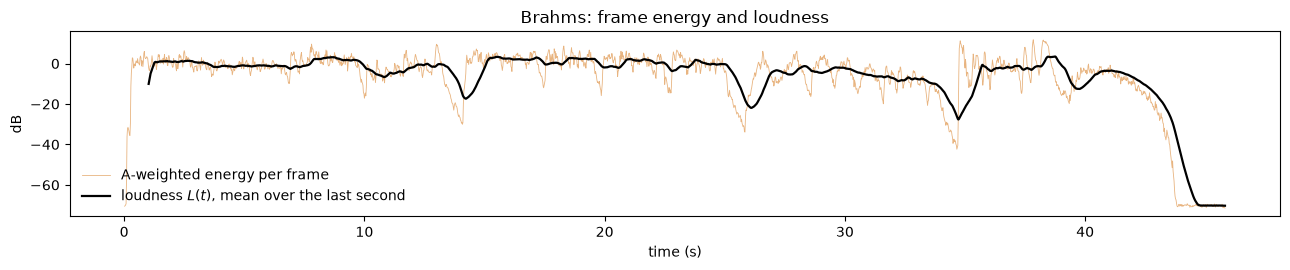

In [19]:
weights = 10 ** (librosa.A_weighting(f, min_db=-100) / 10)   # 10^(A/10) per bin
Fm, _ = frames(music)
Xm = np.abs(np.fft.rfft(Fm * w, axis=1))
frame_db = 10 * np.log10((weights * Xm ** 2).sum(axis=1) / (len(f) - 1))
loudness = np.convolve(frame_db, np.ones(50) / 50)[:len(frame_db)]   # mean over the last 50 frames

t_m = np.arange(len(frame_db)) * 0.020 + 0.020
fig, ax = plt.subplots(figsize=(13, 2.8))
ax.plot(t_m, frame_db, color=MUSIC_C, lw=0.6, alpha=0.6, label="A-weighted energy per frame")
ax.plot(t_m[50:], loudness[50:], color="black", lw=1.6, label="loudness $L(t)$, mean over the last second")
ax.set(xlabel="time (s)", ylabel="dB", title="Brahms: frame energy and loudness")
ax.legend(frameon=False, loc="lower left")
fig.tight_layout()
plt.show()

The loudness follows the dynamics of the orchestra, the rest around 34 seconds and the fade-out
at the end, without the jitter of single frames.

## 10. The Mel Scale and the Filter Bank

Pitch perception is not linear in frequency either: listeners judge the step from 100 to 200 Hz
as large and the step from 10,000 to 10,100 Hz as tiny. The mel scale measures pitch so that equal
distances sound like equal steps:

$$
\text{mel}(f) = 1125 \cdot \ln\left(1 + \frac{f}{700}\right), \qquad f(\text{mel}) = 700 \cdot \left(e^{\text{mel} / 1125} - 1\right)
$$

A filter bank of $B = 26$ triangular bands between 300 and 8000 Hz places $B + 2 = 28$ band edges
equally spaced in mel.

In [20]:
mel = lambda f: 1125 * np.log(1 + np.asarray(f, float) / 700)
mel_inv = lambda m: 700 * (np.exp(np.asarray(m, float) / 1125) - 1)

B, f_lo, f_hi = 26, 300, 8000
step_mel = (mel(f_hi) - mel(f_lo)) / (B + 1)
fc = mel_inv(mel(f_lo) + np.arange(B + 2) * step_mel)   # band edges f_c(0) ... f_c(27)

print_table(
    [["mel(300), mel(8000)", f"{mel(f_lo):.2f}, {mel(f_hi):.2f}"],
     ["distance of the band edges", f"{step_mel:.2f} mel"],
     ["band 1: start, peak, end", f"{fc[0]:.0f}, {fc[1]:.0f}, {fc[2]:.0f} Hz (width {fc[2] - fc[0]:.0f} Hz)"],
     ["band 26: start, peak, end", f"{fc[25]:.0f}, {fc[26]:.0f}, {fc[27]:.0f} Hz (width {fc[27] - fc[25]:.0f} Hz)"]],
    headers=["Quantity", "Value"],
)

| Quantity                   | Value                               |
|:---------------------------|:------------------------------------|
| mel(300), mel(8000)        | 401.26, 2835.00                     |
| distance of the band edges | 90.14 mel                           |
| band 1: start, peak, end   | 300, 383, 474 Hz (width 174 Hz)     |
| band 26: start, peak, end  | 6712, 7330, 8000 Hz (width 1288 Hz) |

Band $b$ rises linearly from $f_c(b-1)$ to its peak at $f_c(b)$ and falls back to 0 at
$f_c(b+1)$. For the bins of our 40 ms frames, the weights $d(b,k)$ form a matrix of 26 rows and
442 columns.

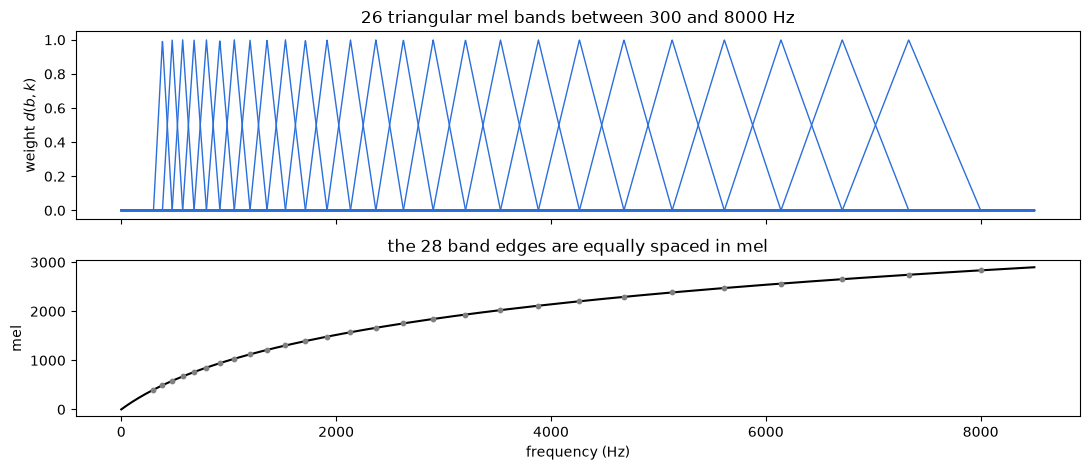

Matrix $d(b,k)$: 26 bands x 442 bins; it matches `mel_bank()` of `ch11_audio.py`: **True**

In [21]:
D = np.zeros((B, len(f)))                               # d(b,k)
for b in range(1, B + 1):
    up = (f - fc[b - 1]) / (fc[b] - fc[b - 1])
    down = (fc[b + 1] - f) / (fc[b + 1] - fc[b])
    D[b - 1] = np.clip(np.minimum(up, down), 0, None)

f_fine = np.linspace(0, 8500, 4000)                     # a fine grid only for drawing the triangles
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 4.8), sharex=True, gridspec_kw=dict(height_ratios=[1.2, 1]))
for b in range(1, B + 1):
    a1.plot(f_fine, np.clip(np.minimum((f_fine - fc[b - 1]) / (fc[b] - fc[b - 1]),
                                       (fc[b + 1] - f_fine) / (fc[b + 1] - fc[b])), 0, None), color=SPEECH_C, lw=1)
a1.set(ylabel="weight $d(b,k)$", title="26 triangular mel bands between 300 and 8000 Hz")
a2.plot(f_fine, mel(f_fine), color="black")
a2.scatter(fc, mel(fc), s=10, color="gray", zorder=3)
a2.set(xlabel="frequency (Hz)", ylabel="mel", title="the 28 band edges are equally spaced in mel")
fig.tight_layout()
plt.show()

display_md(f"Matrix $d(b,k)$: {D.shape[0]} bands x {D.shape[1]} bins; it matches `mel_bank()` of "
           f"`ch11_audio.py`: **{np.allclose(D, mel_bank(N))}**")

The last band is more than seven times wider than the first, as the ear resolves high
frequencies more coarsely.

## 11. MFCCs in Five Steps

The mel-frequency cepstral coefficients combine the filter bank with the logarithmic loudness
perception of the ear. We compute them for the reading.

**Step 1, spectrum.** Window each frame with a Hamming window and compute $|X(t,k)|^2$.

In [22]:
F, N = frames(speech)
P = np.abs(np.fft.rfft(F * np.hamming(N), axis=1)) ** 2     # (frames, 442)

**Step 2, mel spectrum.** Sum the energy in each band, weighted with the triangles:
$M(t,b) = \sum_{k} d(b,k) \cdot |X(t,k)|^2$. The 442 bins shrink to 26 band energies.

In [23]:
Mel = P @ D.T                                           # (frames, 26)

**Step 3, logarithm.** Replace each band energy by $\log M(t,b)$. A change of recording level
becomes a constant offset.

In [24]:
logMel = np.log(Mel + 1e-10)

**Step 4, cepstral coefficients.** A discrete cosine transform of the 26 log energies, of which
we keep the first 13:

$$
c(t,j) = \sum_{b=1}^{B} \log M(t,b) \cdot \cos\left(\frac{j\,(2b-1)\,\pi}{2B}\right), \qquad 0 \le j \le 12
$$

In [25]:
j = np.arange(13)[:, None]
b = np.arange(1, B + 1)[None, :]
DCT = np.cos(j * (2 * b - 1) * np.pi / (2 * B))         # (13, 26)
c = logMel @ DCT.T                                      # (frames, 13)

**Step 5, derivatives.** The first and second differences over neighboring frames,
$\Delta c(t,j) = (c(t+1,j) - c(t-1,j))/2$, describe the transitions between sounds.

In [26]:
dc = np.zeros_like(c)
dc[1:-1] = (c[2:] - c[:-2]) / 2
ddc = np.zeros_like(c)
ddc[1:-1] = (dc[2:] - dc[:-2]) / 2
vectors = np.hstack([c, dc, ddc])

display_md(f"**{vectors.shape[0]} frames x {vectors.shape[1]} values** (13 coefficients, 13 first "
           f"and 13 second differences). Same as `mfcc()` of `ch11_audio.py`: "
           f"**{np.allclose(vectors, mfcc(speech))}**")

**741 frames x 39 values** (13 coefficients, 13 first and 13 second differences). Same as `mfcc()` of `ch11_audio.py`: **True**

What do 13 coefficients keep? The inverse cosine transform of the first coefficients rebuilds a
smooth version of the 26 log energies: the envelope of the spectrum, which reflects the vocal
tract and the timbre. The fewer coefficients we keep, the smoother the curve.

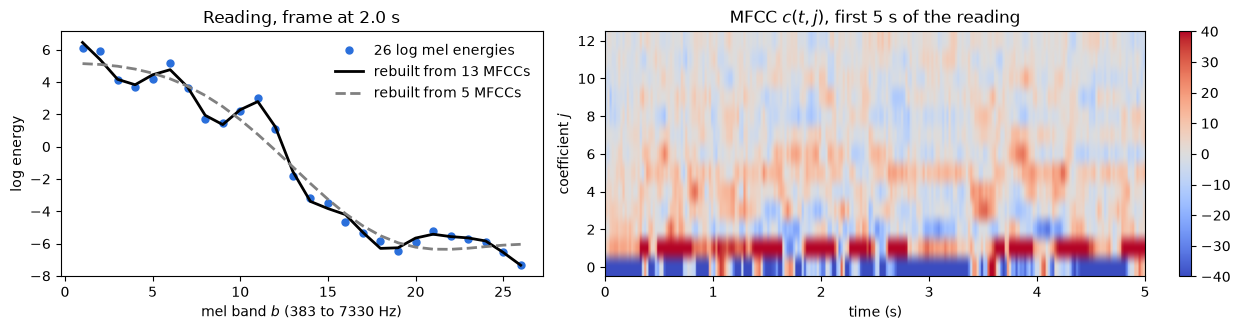

In [27]:
i = int(2.0 / 0.020)                                    # the vowel frame of section 3
inv = np.r_[1 / B, np.full(12, 2 / B)][:, None] * DCT   # inverse of this cosine transform, row j
rebuild = lambda m: inv[:m].T @ c[i, :m]                # 26 values from the first m coefficients
band = np.arange(1, B + 1)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.4), gridspec_kw=dict(width_ratios=[1, 1.4]))
a1.plot(band, logMel[i], "o", color=SPEECH_C, ms=5, label="26 log mel energies")
a1.plot(band, rebuild(13), color="black", lw=2, label="rebuilt from 13 MFCCs")
a1.plot(band, rebuild(5), color="gray", lw=2, ls="--", label="rebuilt from 5 MFCCs")
a1.set(xlabel=f"mel band $b$ ({fc[1]:.0f} to {fc[26]:.0f} Hz)", ylabel="log energy",
       title=f"Reading, frame at {i * 0.02:.1f} s")
a1.legend(frameon=False)
im = a2.imshow(c[:250].T, aspect="auto", origin="lower", cmap="coolwarm",
               extent=(0, 250 * 0.02, -0.5, 12.5), vmin=-40, vmax=40)
a2.set(xlabel="time (s)", ylabel="coefficient $j$", title="MFCC $c(t,j)$, first 5 s of the reading")
fig.colorbar(im, ax=a2)
fig.tight_layout()
plt.show()

With 13 coefficients, the curve still follows the peaks of the vowel spectrum; with 5, only its
broad shape remains. The heatmap clips the large values of $c(t,0)$, the overall level, and
$c(t,1)$, the tilt, so that the higher coefficients stay visible. They change with each new sound.

<div style="border-left: 4px solid #D97706; background: rgba(217, 119, 6, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#D97706; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">MFCC values depend on the implementation</strong><br>
Libraries differ in the window, the mel formula, the number and range of the bands, the normalization of the triangles, the logarithm base, and the scaling of the cosine transform. The index and the queries must use the same pipeline.
</div>

librosa computes MFCCs with 128 mel bands up to 11,025 Hz, normalized triangles, decibels, and an
orthonormal cosine transform. On the same 40 ms frames, the numbers have little in common with ours:

In [28]:
lib = librosa.feature.mfcc(y=speech, sr=SR, n_mfcc=13, n_fft=N, hop_length=N // 2, center=False).T
print_table(
    [["this notebook (book)"] + [f"{v:.1f}" for v in c[i, :5]] + [f"{c[:, 2].std():.2f}"],
     ["librosa defaults"] + [f"{v:.1f}" for v in lib[i, :5]] + [f"{lib[:, 2].std():.2f}"]],
    headers=["Pipeline", "c0", "c1", "c2", "c3", "c4", "std of c2"],
)

| Pipeline             |     c0 |    c1 |   c2 |    c3 |   c4 |   std of c2 |
|:---------------------|-------:|------:|-----:|------:|-----:|------------:|
| this notebook (book) |  -30.5 |  82.2 |  8.6 |  -9.5 |  0.9 |       10.75 |
| librosa defaults     | -324.9 | 272.5 | 11.3 | -28.2 | 14.7 |       32.98 |

## Payoff: Three Numbers That Separate Talk from Music

The archivist wants to mark the talk and the music. Each new vowel and consonant reshapes the
spectral envelope, while an orchestra holds its timbre longer, so the second coefficient $c(t,2)$
varies more in speech. Together with the mean LSTER and HZCRR of the 4-second segments, we compute
it for six recordings: the three LibriVox readings and three music pieces.

In [29]:
six = ["libri1", "libri2", "libri3", "brahms", "nutcracker", "vibeace"]
rows = []
for name in six:
    y = load(name)
    Ey, Zy = time_features(y)
    s = segment_ratios(Ey, Zy)
    rows.append([CLIPS[name][0], CLIPS[name][1], f"{s[:, 0].mean():.2f}", f"{s[:, 1].mean():.2f}",
                 f"{mfcc(y, deltas=False)[:, 2].std():.2f}"])
print_table(rows, headers=["Recording", "Kind", "mean LSTER", "mean HZCRR", "std of c2"])

| Recording                                  | Kind   |   mean LSTER |   mean HZCRR |   std of c2 |
|:-------------------------------------------|:-------|-------------:|-------------:|------------:|
| LibriVox reading 1 (The Ashiel Mystery)    | speech |         0.47 |         0.19 |       10.75 |
| LibriVox reading 2 (The Age of Chivalry)   | speech |         0.51 |         0.16 |       12.84 |
| LibriVox reading 3 (Northanger Abbey)      | speech |         0.53 |         0.18 |       10.5  |
| Brahms, Hungarian Dance No. 5              | music  |         0.35 |         0.09 |        7.26 |
| Tchaikovsky, Dance of the Sugar Plum Fairy | music  |         0.31 |         0.07 |        9.99 |
| Vibe Ace (jazz)                            | music  |         0.41 |         0.18 |        7.76 |

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">Features describe how a sound is heard</strong><br>
All three readings have a higher mean LSTER and a higher standard deviation of $c(t,2)$ than all three music pieces. No single number on raw amplitudes could say this; frame features summarized per segment can. HZCRR alone does not separate them: the jazz piece Vibe Ace, with its drums and decaying vibraphone, lies among the readings. Demo ch11-03 builds a classifier from these segment features and shows where it fails.
</div>

## Summary

- A recording is a list of samples. The sampling rate fixes the highest frequency ($f_s / 2$), and
  frequencies above it fold back as aliases.
- The short-time Fourier transform turns frames into spectra. The frame duration $T$ fixes the
  frequency resolution $\Delta f = 1/T$; the sampling rate does not.
- Short-time energy and zero-crossing rate describe a frame; LSTER and HZCRR describe how they vary
  over a 4-second segment, and they are higher for speech.
- Centroid, roll-off, bandwidth, flux, and band energy describe the shape of the spectrum; the
  A-weighting turns energy into loudness.
- MFCCs sum the spectrum in mel bands, take the logarithm, and keep 13 cosine coefficients: the
  smooth envelope of the spectrum, which reflects the timbre.

## Try it yourself

1. **Frame length.** Recompute the spectra of section 3 with frames of 10 ms and 160 ms. What
   happens to the peaks of the Brahms frame?
2. **Another threshold.** Some variants of LSTER use one third of the mean energy instead of one
   half. Change `segment_ratios` and rerun the payoff. Do the readings still lie above the music?
3. **Fewer or more bands.** Rebuild the filter bank with $B = 13$ or $B = 40$ and recompute the
   standard deviation of $c(t,2)$ for the six recordings. Does the separation hold?

## Credits

In [30]:
print_table(credits(six), headers=["Clip", "Title", "Attribution", "License"])

| Clip       | Title                                                                  | Attribution                                             | License    |
|:-----------|:-----------------------------------------------------------------------|:--------------------------------------------------------|:-----------|
| libri1     | The Ashiel Mystery                                                     | Marion Bryce (author), Garth Comira (reader)            | CC-BY-4.0  |
| libri2     | The Age of Chivalry, chapter IX: The Adventure of the Cart             | Thomas Bulfinch (author), Anders Lankford (reader)      | CC-BY-4.0  |
| libri3     | Northanger Abbey (librosa metadata: Sense and Sensibility, chapter 18) | Jane Austen (author), Heather Barnett (reader)          | CC-BY-4.0  |
| brahms     | Hungarian Dance number 5                                               | Johannes Brahms (composer), US Army Strings (performer) | CC-PDM-1.0 |
| nutcracker | Dance of the Sugar Plum Fairy                                          | P.I. Tchaikovsky (composer), Kevin MacLeod (arranger)   | CC-BY-4.0  |
| vibeace    | Vibe Ace                                                               | Kevin MacLeod                                           | CC-BY-4.0  |